# Explore: corridor activity profiles

A research-style tour of the 21 corridors side by side: how big they are, how loyal their visitors are, when
people come, where they come from, and how far they travel. The goal is to see **how corridors compare, what
stands out, and which corridors behave alike**.

The notebook reads only the finished outputs of `01_`-`05_` (`corridor_metrics.json` and the processed
tables), so it is safe to re-run at any time and nothing downstream depends on it.

**Reading guide / caveats that apply throughout**

- **One provider at a time.** The corridor-versus-corridor comparisons in sections 1-7 all use the **most recent
  segment (S3, with 2025 as the summary year)**, so every number comes from a single provider. The data also contain an
  earlier provider (S1, 2019-2022); the two are not calibrated to each other (`04_cross_segment_comparability`), so the
  last section compares them only through **rank position**, and only for metrics that passed the rank-stability test.
- **Devices are not people.** A "device" is a phone advertising ID that was seen in the corridor; the "visitors"
  below are devices with a matched Bay Area home, weighted for panel size.
- **Corridors overlap geohash cells** in places, so corridor totals cannot be summed into a number of distinct visitors.
- **Distances** run from the visitor's home *block-group centre* to the corridor *centroid*, so long, thin corridors
  (e.g. Hegenberger, Telegraph) are measured to a single middle point.
- **Small corridors are noisy.** Anything below roughly 1,000 estimated devices a month is flagged with an asterisk.

---

| | |
|---|---|
| **Inputs** | `src/data/activity/corridor_metrics.json`, `corridor_index.json`; `data/activity/processed/*` |
| **Outputs** | Figures and tables in this notebook only |
| **Run after** | `01_` ... `05_` |

In [1]:
import json
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, fcluster, leaves_list, linkage
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", message="Unable to import Axes3D")

/home/aniket/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
# --- Paths ---
# Repo root = nearest parent folder containing package.json, so this notebook runs from any depth.
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "package.json").exists())
DATA = ROOT / "data"                 # raw + intermediate files
SRC_DATA = ROOT / "src" / "data"     # final outputs consumed directly by the web app
PROCESSED_DIR = DATA / "activity" / "processed"

METRICS_JSON = SRC_DATA / "activity" / "corridor_metrics.json"
INDEX_JSON = SRC_DATA / "activity" / "corridor_index.json"
BG_ORIGIN_CSV = PROCESSED_DIR / "corridor_bg_origin_by_segment.csv.gz"
CORRIDOR_DISTRICT_CSV = PROCESSED_DIR / "corridor_districts.csv"
OAK_BG_GEOJSON = SRC_DATA / "OAK_BG.geo.json"
DISTRICTS_GEOJSON = SRC_DATA / "OAK_council_districts.geo.json"
SET2_CORRIDORS_GPKG = DATA / "corridors" / "corridors2" / "corridors2_final_original.gpkg"
MAP_CORRIDORS_GEOJSON = SRC_DATA / "OAK_CORRIDORS.geo.json"

# --- Parameters ---
TIME_PERIODS = ["all", "evening", "nine-five", "weekdays", "weekends"]
SEGMENT = "S3"                     # provider segment profiled in sections 1-7 (the most recent)
SMALL_CORRIDOR_DEVICES = 1000       # below this many estimated devices/month, flag as small-sample
WEEKEND_BASELINE = 200 / 7          # 2 of 7 days: weekend share of visits if there were no weekend skew
N_CLUSTERS = 3          # 3 is stable across feature choices; at 4 the tiny Uptown corridor splits off alone
CLUSTER_FEATURES = ["median_km", "oakland_pct", "repeat_pct", "weekend_pct", "evening_pct", "log_devices"]
WORK_CRS = "EPSG:3310"

# --- Chart styling (see dataviz skill: fixed categorical order, single-hue sequential) ---
CATEGORICAL_PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQUENTIAL_BLUE_RAMP = ["#cde2fb", "#9ec3f2", "#6da7ec", "#2a78d6", "#1f62b4", "#184f95", "#0f3563"]
SET_COLORS = {1: CATEGORICAL_PALETTE[0], 2: CATEGORICAL_PALETTE[1]}
CHART_GRID_COLOR = "#e1e0d9"
CHART_MUTED_TEXT = "#898781"
MAP_BASE = "#eceae3"

In [3]:
def style_axis(ax, grid_axis="y"):
    """Shared cosmetic cleanup: recessive grid, no top/right spines."""
    ax.grid(axis=grid_axis, color=CHART_GRID_COLOR, linewidth=0.6, zorder=0)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    ax.tick_params(colors=CHART_MUTED_TEXT)


def label_points(ax, x, y, names, fontsize=7.5, dx=4, dy=3):
    for xi, yi, n in zip(x, y, names):
        ax.annotate(n, (xi, yi), xytext=(dx, dy), textcoords="offset points", fontsize=fontsize, color="#3a3a38")


def short(name, n=22):
    return name if len(name) <= n else name[: n - 1] + "..."


def facts_for(df, col, label, unit="", high="highest", low="lowest", k=3, fmt="{:.1f}"):
    """Print the top/bottom k corridors for one metric as a short bulleted list."""
    s = df[col].dropna().sort_values(ascending=False)
    top = ", ".join(f"{df.loc[i, 'label']} ({fmt.format(v)}{unit})" for i, v in s.head(k).items())
    bot = ", ".join(f"{df.loc[i, 'label']} ({fmt.format(v)}{unit})" for i, v in s.tail(k)[::-1].items())
    print(f"- **{label}**: {high}: {top}. {low}: {bot}.")

## Build the corridor profile table

One row per corridor, combining the headline metrics from `corridor_metrics.json` with three measures that only
the block-group table can give us:

- **Origin concentration (HHI)**: how concentrated a corridor's *Oakland-origin* visitors are across block
  groups (sum of squared shares; 1 = all from one block group, small = spread evenly).
- **# block groups for half of Oakland-origin visitors**: the footprint of the core catchment.
- **Share from the nearest 10 block groups**: how quickly the catchment falls off.

In [4]:
with open(METRICS_JSON) as f:
    M = json.load(f)
with open(INDEX_JSON) as f:
    index = {e["id"]: e for e in json.load(f)}
meta, C = M["meta"], M["corridors"]

district_info = pd.read_csv(CORRIDOR_DISTRICT_CSV).set_index("corridor_slug")
bg_origin = pd.read_csv(BG_ORIGIN_CSV, dtype={"bg_geoid": str})
bg_origin = bg_origin[bg_origin.segment == SEGMENT]

rows = []
for slug, c in C.items():
    seg = c["segments"][SEGMENT]
    s, sp, td, ob = seg["summary"], seg["splits"], seg["travel_distance"]["all"], seg["origin_by_area"]["all"]
    rows.append({
        "slug": slug, "name": c["name"], "set": index[slug]["corridor_set"], "district": index[slug]["primary_district"],
        "area_ha": index[slug]["area_hectares"],
        "devices_per_month": s["devices_per_month"], "visits_per_device": s["visits_per_device"], "repeat_pct": s["repeat_pct"],
        "weekend_pct": sp["weekend_pct"], "evening_pct": sp["evening_pct"],
        "oakland_pct": ob["oakland"], "sf_pct": ob["san_francisco"], "rest_east_bay_pct": ob["rest_east_bay"], "rest_bay_area_pct": ob["rest_bay_area"],
        "in_district_pct": s["in_district_pct"],
        "median_km": td["median_km"], "mean_km": td["mean_km"],
        "within_5km_pct": td["bands"][0] + td["bands"][1],
        "beyond_25km_pct": sum(td["bands"][4:]),
    })
prof = pd.DataFrame(rows).set_index("slug")

# block-group concentration from the interpolated Oakland origin shares (period = all)
conc = {}
for slug, g in bg_origin[bg_origin.time_period == "all"].groupby("corridor_slug"):
    shares = g.pct_share.sort_values(ascending=False).to_numpy()
    shares = shares / shares.sum()
    conc[slug] = {
        "hhi_bg": float((shares ** 2).sum()),
        "n_bg_half": int(np.searchsorted(np.cumsum(shares), 0.5) + 1),
        "top10_bg_share": float(shares[:10].sum() * 100),
    }
prof = prof.join(pd.DataFrame(conc).T)

prof["devices_per_ha"] = prof.devices_per_month / prof.area_ha
prof["weekend_index"] = prof.weekend_pct / WEEKEND_BASELINE        # 1.0 = no weekend skew
prof["log_devices"] = np.log10(prof.devices_per_month)
prof["small"] = prof.devices_per_month < SMALL_CORRIDOR_DEVICES
prof["label"] = prof.name.map(lambda n: short(n)) + np.where(prof.small, "*", "")

print(f"{len(prof)} corridors; {prof.small.sum()} flagged small-sample (*): {', '.join(prof[prof.small].name)}")
prof[["label", "set", "district", "area_ha", "devices_per_month", "visits_per_device", "repeat_pct", "weekend_pct", "evening_pct", "oakland_pct", "in_district_pct", "median_km"]].round(1).sort_values("devices_per_month", ascending=False)

21 corridors; 3 flagged small-sample (*): Montclair, Uptown Arts & Entertainment District, Northlake


,label,set,district,area_ha,devices_per_month,visits_per_device,repeat_pct,weekend_pct,evening_pct,oakland_pct,in_district_pct,median_km
slug,,,,,,,,,,,,
hegenberger,Hegenberger,2,7,351.6,8843,1.7,25.5,26.2,44.1,39.8,18.6,11.0
fruitvale,Fruitvale,1,5,38.7,7730,1.7,28.2,28.5,54.0,52.7,22.8,6.0
lake_merritt,Lake Merritt,1,3,57.5,7331,1.8,28.1,27.7,46.7,42.7,20.4,11.2
elmhurst,Elmhurst,2,7,106.3,6333,1.8,28.8,28.3,54.8,54.8,30.6,5.1
downtown,Downtown,1,3,41.7,5919,1.7,26.7,27.5,40.0,40.9,16.2,11.8
bambd,BAMBD,2,3,56.4,5472,1.8,28.8,28.0,52.6,50.2,29.3,9.0
chinatown,Chinatown,1,2,61.6,5363,1.8,25.4,28.2,34.4,38.5,12.8,11.1
temescal_telegraph,Temescal/Telegraph,1,1,49.2,5054,1.7,26.3,27.9,46.8,41.0,16.8,10.0
jack_london,Jack London,1,3,84.6,4424,1.7,23.0,29.9,47.7,36.5,13.9,12.4


## 1. The corridors: where they are and how big

Set 1 (blue) are the 11 Oakland BIDs; set 2 (orange) are the ten additional corridors.

/tmp/ipykernel_81044/1323509160.py:21: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend(frameon=False, loc="lower left")
/tmp/ipykernel_81044/1323509160.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False, loc="lower left")


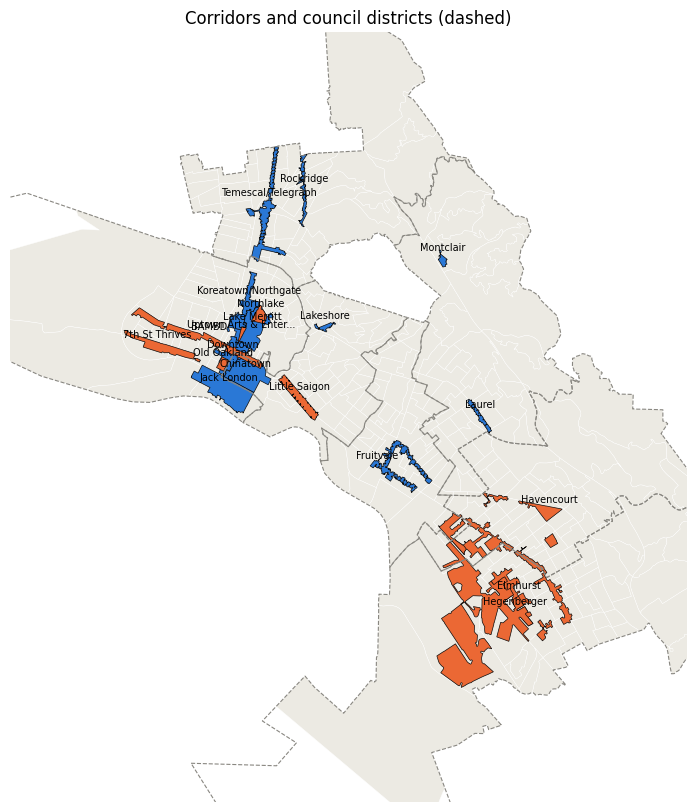

In [5]:
oak_bg = gpd.read_file(OAK_BG_GEOJSON)[["GEOID", "geometry"]].to_crs(WORK_CRS)
districts = gpd.read_file(DISTRICTS_GEOJSON).to_crs(WORK_CRS)

# polygons for all 21: map polygons for set 1, queried gpkg for set 2 (has Hegenberger)
map_corr = gpd.read_file(MAP_CORRIDORS_GEOJSON).to_crs(WORK_CRS)
map_corr["name"] = map_corr.corridor_name.str.replace("\xa0", " ").str.strip()
set2 = gpd.read_file(SET2_CORRIDORS_GPKG).to_crs(WORK_CRS)
set2["name"] = set2.corridor_name
corr_geo = pd.concat([map_corr[map_corr.name.isin(prof[prof.set == 1].name)][["name", "geometry"]], set2[["name", "geometry"]]])
corr_geo = corr_geo.merge(prof.reset_index()[["slug", "name", "set", "devices_per_month"]], on="name")
corr_geo = gpd.GeoDataFrame(corr_geo, geometry="geometry", crs=WORK_CRS)

fig, ax = plt.subplots(figsize=(10, 10))
oak_bg.plot(ax=ax, color=MAP_BASE, edgecolor="white", linewidth=0.3)
districts.boundary.plot(ax=ax, color=CHART_MUTED_TEXT, linewidth=0.8, linestyle="--")
for set_id, g in corr_geo.groupby("set"):
    g.plot(ax=ax, color=SET_COLORS[set_id], edgecolor="#0b0b0b", linewidth=0.5, label=f"Set {set_id}")
for _, r in corr_geo.iterrows():
    pt = r.geometry.representative_point()
    ax.annotate(short(r["name"], 20), (pt.x, pt.y), xytext=(0, 6), textcoords="offset points", fontsize=7, ha="center")
ax.legend(frameon=False, loc="lower left")
ax.set_title("Corridors and council districts (dashed)")
ax.set_axis_off(); ax.set_aspect("equal")
xmin, ymin, xmax, ymax = corr_geo.total_bounds
ax.set_xlim(xmin - 3000, xmax + 3000); ax.set_ylim(ymin - 3000, ymax + 3000)
plt.show()

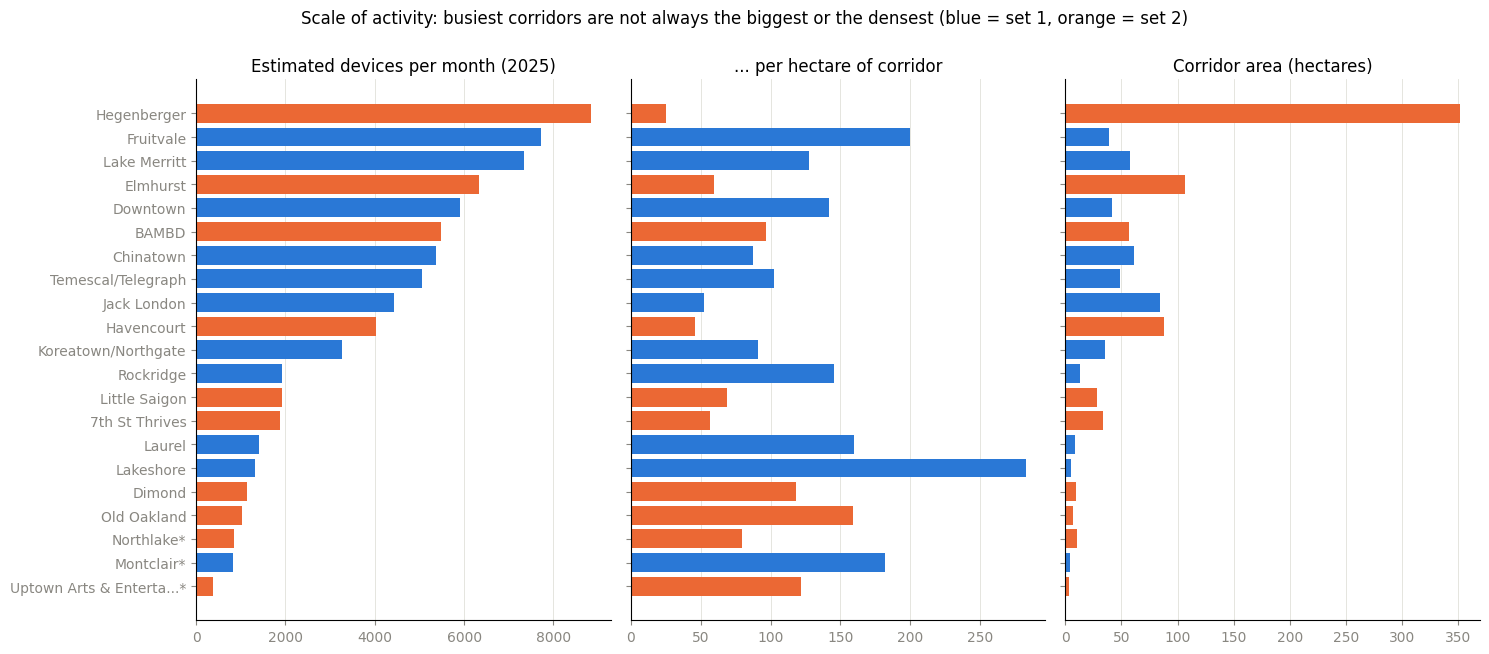

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6.5), sharey=True)
order = prof.sort_values("devices_per_month")
colors = [SET_COLORS[s] for s in order.set]

axes[0].barh(order.label, order.devices_per_month, color=colors)
axes[0].set_title("Estimated devices per month (2025)")
style_axis(axes[0], "x")

axes[1].barh(order.label, order.devices_per_ha, color=colors)
axes[1].set_title("... per hectare of corridor")
style_axis(axes[1], "x")

axes[2].barh(order.label, order.area_ha, color=colors)
axes[2].set_title("Corridor area (hectares)")
style_axis(axes[2], "x")
plt.suptitle("Scale of activity: busiest corridors are not always the biggest or the densest (blue = set 1, orange = set 2)", y=1.0)
plt.tight_layout()
plt.show()

## 2. Loyalty and intensity

Two ways to say "do people come back?": **repeat-visitor %** (seen on at least two days in a half-year) and
**visits per device per month**. Both are 2025 (S3) values, compared between corridors only.

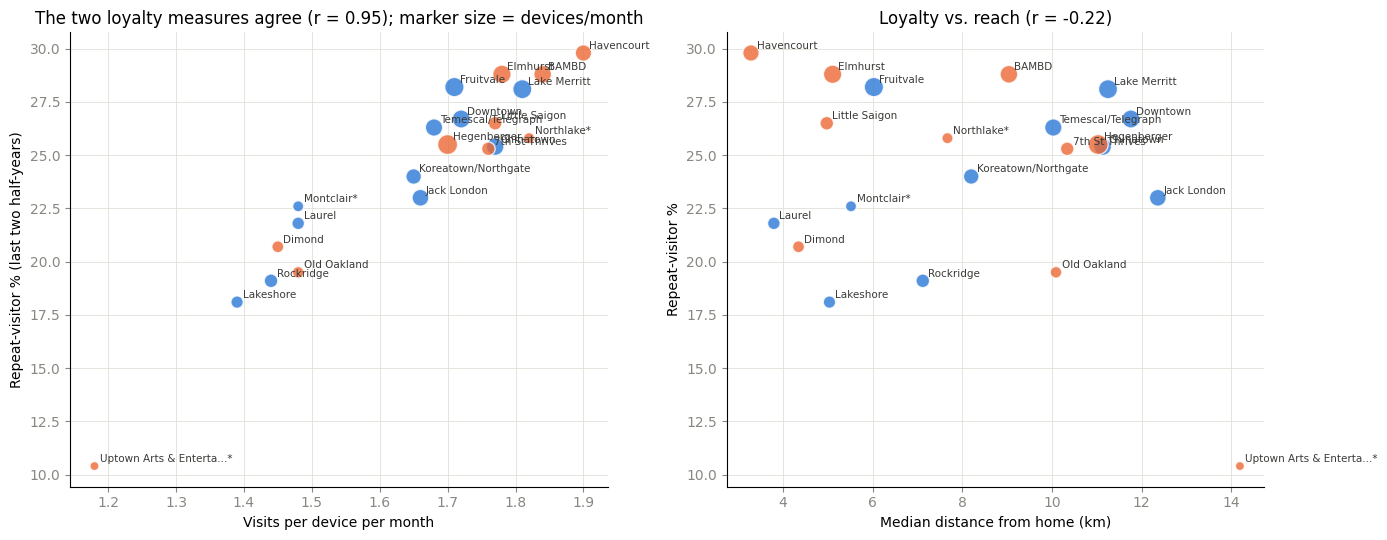

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

ax = axes[0]
ax.scatter(prof.visits_per_device, prof.repeat_pct, s=np.sqrt(prof.devices_per_month) * 2.2, c=[SET_COLORS[s] for s in prof.set], alpha=0.8, zorder=3, edgecolor="white")
label_points(ax, prof.visits_per_device, prof.repeat_pct, prof.label)
r = prof[["visits_per_device", "repeat_pct"]].corr().iloc[0, 1]
ax.set_xlabel("Visits per device per month"); ax.set_ylabel("Repeat-visitor % (last two half-years)")
ax.set_title(f"The two loyalty measures agree (r = {r:.2f}); marker size = devices/month")
style_axis(ax, "both")

ax = axes[1]
ax.scatter(prof.median_km, prof.repeat_pct, s=np.sqrt(prof.devices_per_month) * 2.2, c=[SET_COLORS[s] for s in prof.set], alpha=0.8, zorder=3, edgecolor="white")
label_points(ax, prof.median_km, prof.repeat_pct, prof.label)
r2 = prof[["median_km", "repeat_pct"]].corr().iloc[0, 1]
ax.set_xlabel("Median distance from home (km)"); ax.set_ylabel("Repeat-visitor %")
ax.set_title(f"Loyalty vs. reach (r = {r2:.2f})")
style_axis(ax, "both")
plt.tight_layout()
plt.show()

## 3. When people come

Two questions: how far a corridor skews to the weekend, and how far it skews to the evening.

- **Weekend index** = weekend share of visits divided by 2/7 (the share if every day were equal). Above 1 =
  weekend-leaning, below 1 = weekday-leaning (office/commuter pattern).
- **Evening share** = evening visits / (evening + weekday-daytime visits). The two windows are unequal in length and
  the evening window includes weekends, so read it only *relative to other corridors*.

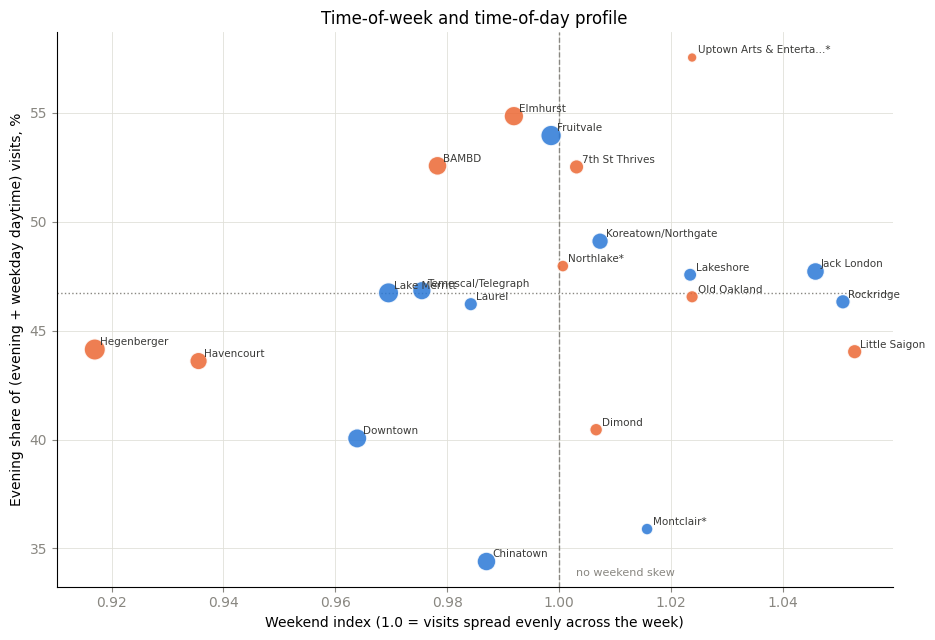

In [8]:
fig, ax = plt.subplots(figsize=(9.5, 6.5))
ax.scatter(prof.weekend_index, prof.evening_pct, s=np.sqrt(prof.devices_per_month) * 2.5, c=[SET_COLORS[s] for s in prof.set], alpha=0.85, zorder=3, edgecolor="white")
label_points(ax, prof.weekend_index, prof.evening_pct, prof.label)
ax.axvline(1, color=CHART_MUTED_TEXT, linestyle="--", linewidth=1)
ax.axhline(prof.evening_pct.median(), color=CHART_MUTED_TEXT, linestyle=":", linewidth=1)
ax.text(1.003, ax.get_ylim()[0] + 0.5, "no weekend skew", color=CHART_MUTED_TEXT, fontsize=8)
ax.set_xlabel("Weekend index (1.0 = visits spread evenly across the week)")
ax.set_ylabel("Evening share of (evening + weekday daytime) visits, %")
ax.set_title("Time-of-week and time-of-day profile")
style_axis(ax, "both")
plt.tight_layout()
plt.show()

## 4. Where people come from

How *local* is each corridor? Three lenses on the same question: share of visitors from **Oakland**, from the
corridor's **own council district**, and the **median distance** visitors travel.

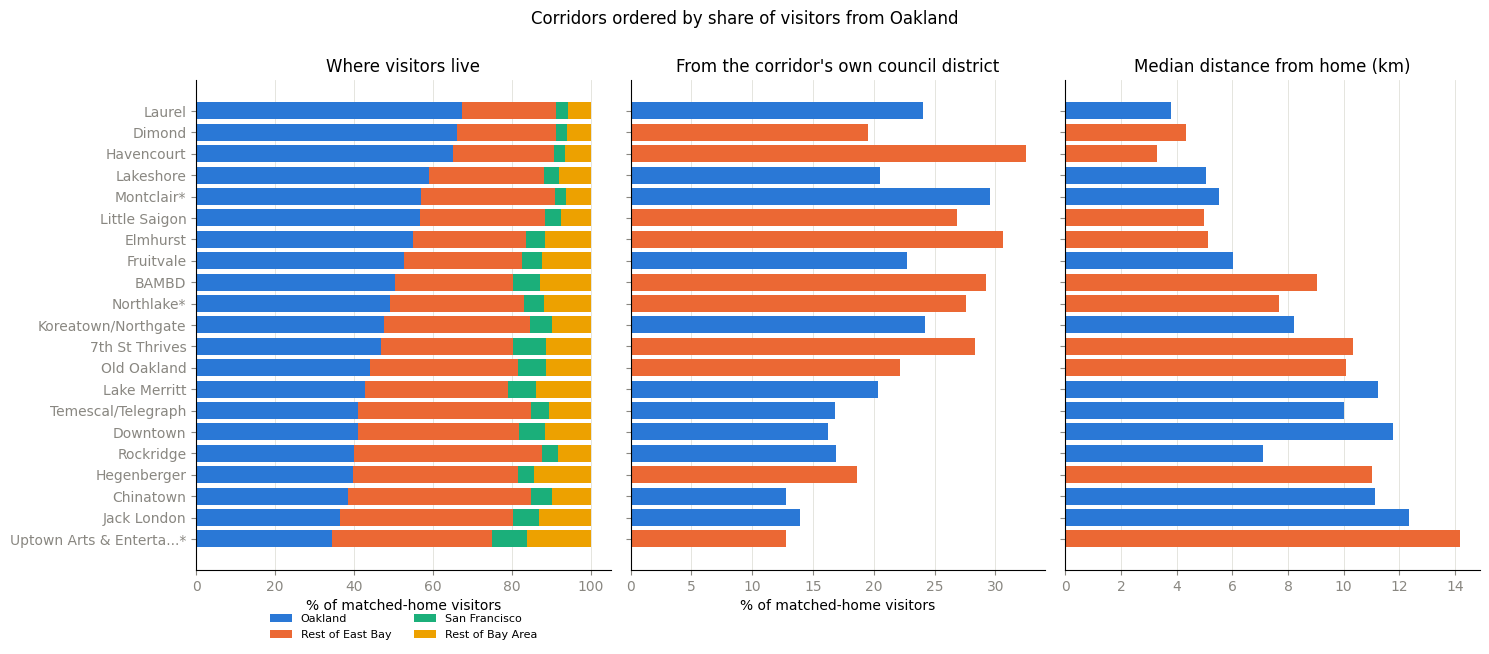

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6.5), sharey=True)
order = prof.sort_values("oakland_pct")
colors = [SET_COLORS[s] for s in order.set]

left = np.zeros(len(order))
for color, col, lab in zip(CATEGORICAL_PALETTE, ["oakland_pct", "rest_east_bay_pct", "sf_pct", "rest_bay_area_pct"],
                           ["Oakland", "Rest of East Bay", "San Francisco", "Rest of Bay Area"]):
    axes[0].barh(order.label, order[col], left=left, color=color, label=lab)
    left += order[col].values
axes[0].set_title("Where visitors live")
axes[0].set_xlabel("% of matched-home visitors")
axes[0].legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.07), fontsize=8)
style_axis(axes[0], "x")

axes[1].barh(order.label, order.in_district_pct, color=colors)
axes[1].set_title("From the corridor's own council district")
axes[1].set_xlabel("% of matched-home visitors")
style_axis(axes[1], "x")

axes[2].barh(order.label, order.median_km, color=colors)
axes[2].set_title("Median distance from home (km)")
style_axis(axes[2], "x")
plt.suptitle("Corridors ordered by share of visitors from Oakland", y=1.0)
plt.tight_layout()
plt.show()

### How tightly is each catchment packed?

The Oakland-origin visitors of some corridors sit in a handful of nearby block groups; others spread over most of
the city. **Half of the Oakland-origin visitors** come from how many of the 354 block groups, and how much of the
total do the **ten biggest** block groups provide?

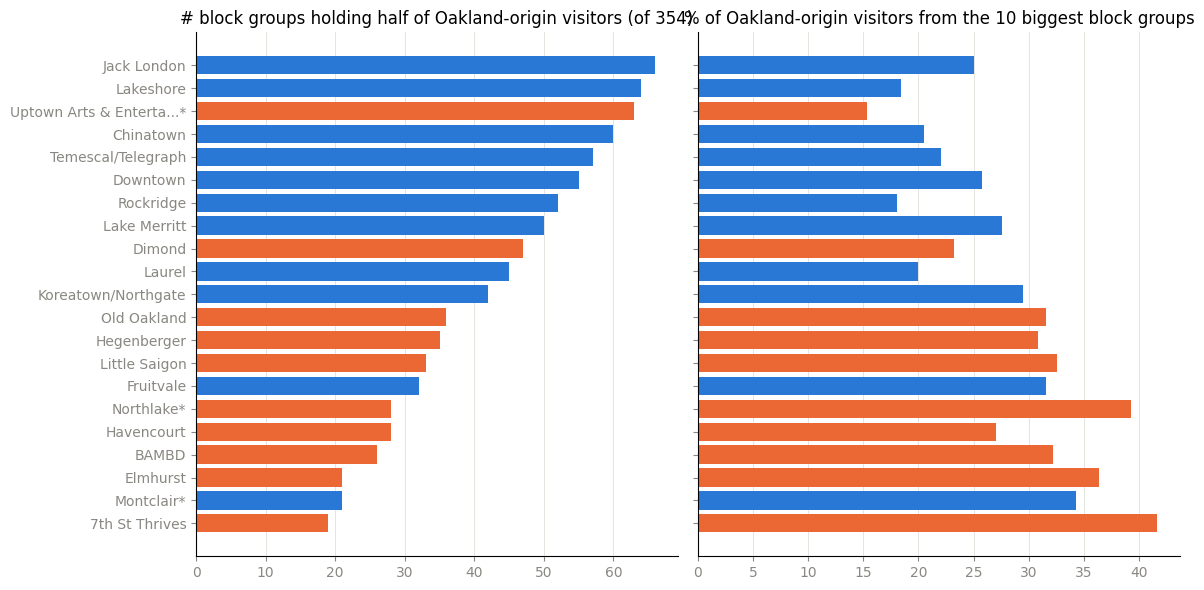

Correlation between catchment footprint (# BGs for half) and median distance: 0.42


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
order = prof.sort_values("n_bg_half")
colors = [SET_COLORS[s] for s in order.set]
axes[0].barh(order.label, order.n_bg_half, color=colors)
axes[0].set_title("# block groups holding half of Oakland-origin visitors (of 354)")
style_axis(axes[0], "x")
axes[1].barh(order.label, order.top10_bg_share, color=colors)
axes[1].set_title("% of Oakland-origin visitors from the 10 biggest block groups")
style_axis(axes[1], "x")
plt.tight_layout()
plt.show()

print(f"Correlation between catchment footprint (# BGs for half) and median distance: {prof.n_bg_half.corr(prof.median_km):.2f}")

## 5. Does reach change with time of day and week?

The five periods let us ask whether a corridor draws from further away in the evening or on weekends. Compare
the median travel distance and Oakland share across periods.

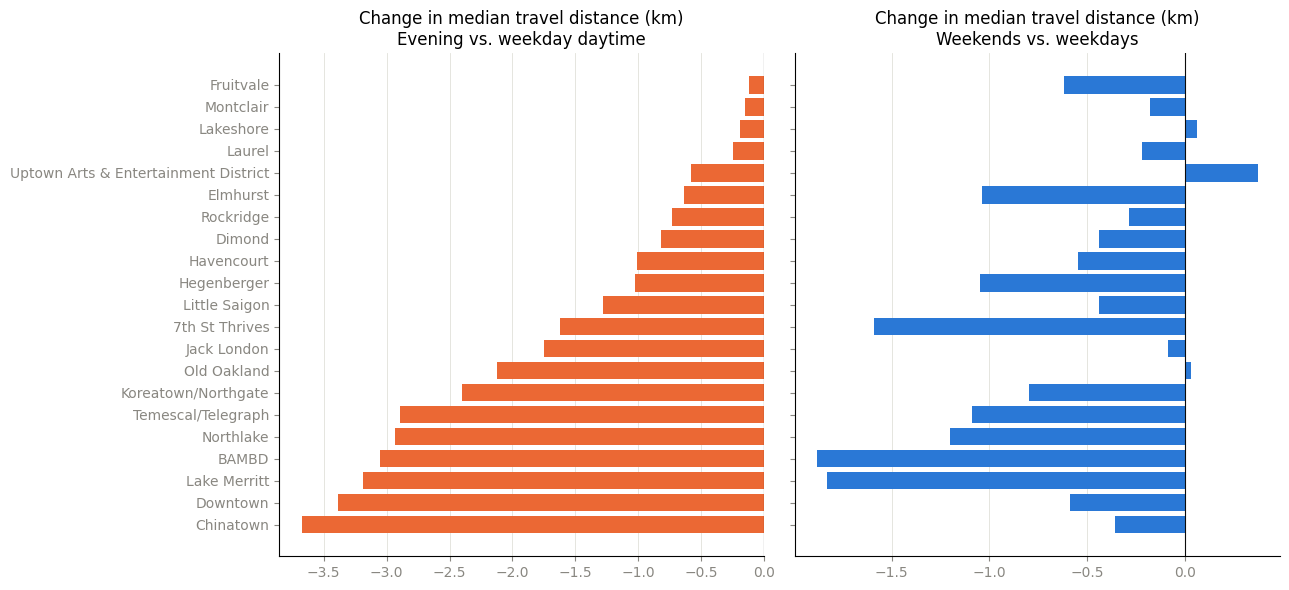

,evening vs daytime (km),weekend vs weekday (km),evening vs daytime (Oakland pts),weekend vs weekday (Oakland pts)
Chinatown,-3.7,-0.4,7.6,-0.2
Downtown,-3.4,-0.6,6.7,1.1
Lake Merritt,-3.2,-1.8,5.9,3.0
BAMBD,-3.0,-1.9,6.8,3.5
Northlake,-2.9,-1.2,8.5,2.9
Temescal/Telegraph,-2.9,-1.1,2.5,1.8
Koreatown/Northgate,-2.4,-0.8,4.7,1.6
Old Oakland,-2.1,0.0,3.8,-0.4
Jack London,-1.8,-0.1,3.8,1.1
7th St Thrives,-1.6,-1.6,2.9,4.2


In [11]:
by_period = pd.DataFrame({
    p: {slug: C[slug]["segments"][SEGMENT]["travel_distance"][p]["median_km"] for slug in C} for p in TIME_PERIODS
}).rename(index=prof.name)
oak_by_period = pd.DataFrame({
    p: {slug: C[slug]["segments"][SEGMENT]["origin_by_area"][p]["oakland"] for slug in C} for p in TIME_PERIODS
}).rename(index=prof.name)

shift = pd.DataFrame({
    "evening vs daytime (km)": by_period["evening"] - by_period["nine-five"],
    "weekend vs weekday (km)": by_period["weekends"] - by_period["weekdays"],
    "evening vs daytime (Oakland pts)": oak_by_period["evening"] - oak_by_period["nine-five"],
    "weekend vs weekday (Oakland pts)": oak_by_period["weekends"] - oak_by_period["weekdays"],
})

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
order = shift.sort_values("evening vs daytime (km)").index
axes[0].barh(order, shift.loc[order, "evening vs daytime (km)"], color=CATEGORICAL_PALETTE[1], label="Evening minus weekday daytime")
axes[0].set_title("Change in median travel distance (km)\nEvening vs. weekday daytime")
axes[0].axvline(0, color="#0b0b0b", linewidth=0.8)
style_axis(axes[0], "x")
axes[1].barh(order, shift.loc[order, "weekend vs weekday (km)"], color=CATEGORICAL_PALETTE[0])
axes[1].set_title("Change in median travel distance (km)\nWeekends vs. weekdays")
axes[1].axvline(0, color="#0b0b0b", linewidth=0.8)
style_axis(axes[1], "x")
plt.tight_layout()
plt.show()

shift.round(1).sort_values("evening vs daytime (km)")

## 6. A single picture: standardised profile and corridor types

Each metric is turned into a z-score (corridor value minus the corridor average, in standard deviations), then
corridors are grouped by hierarchical (Ward) clustering on six features: median distance, Oakland share,
repeat %, weekend share, evening share and (log) activity level. The heatmap is ordered by the clustering so
that similar corridors sit together.

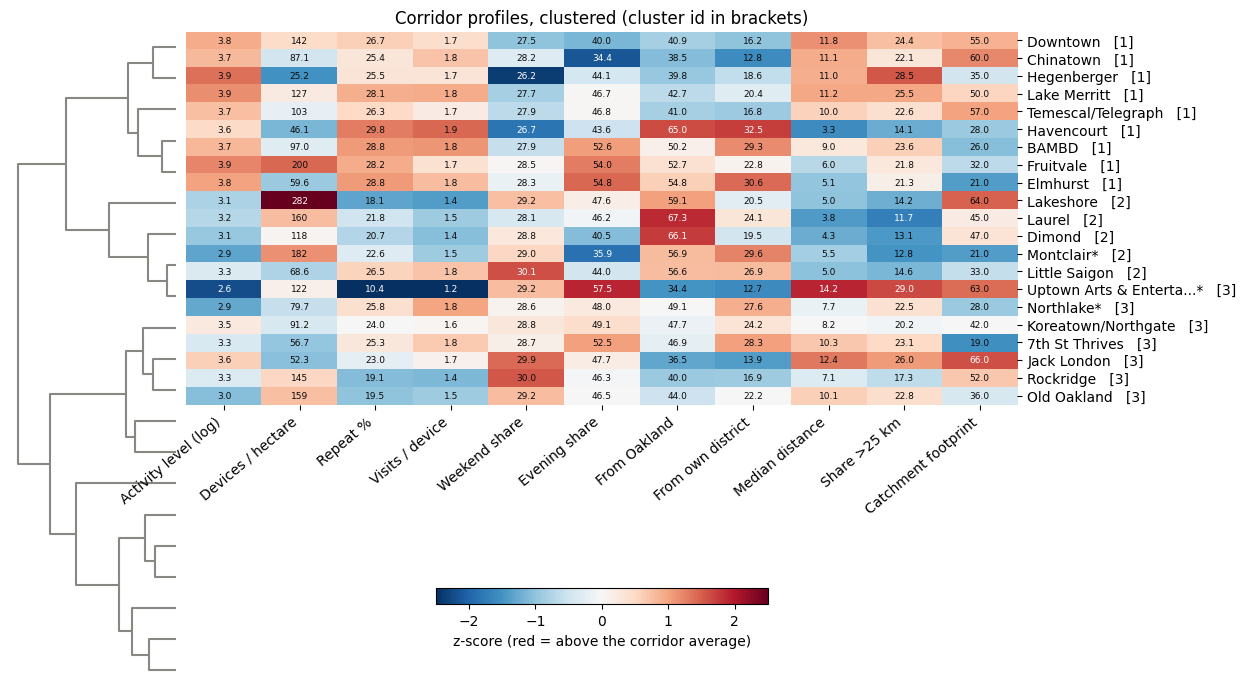

In [12]:
heat_cols = ["log_devices", "devices_per_ha", "repeat_pct", "visits_per_device", "weekend_pct", "evening_pct", "oakland_pct", "in_district_pct", "median_km", "beyond_25km_pct", "n_bg_half"]
heat_labels = ["Activity level (log)", "Devices / hectare", "Repeat %", "Visits / device", "Weekend share", "Evening share", "From Oakland", "From own district", "Median distance", "Share >25 km", "Catchment footprint"]

z = (prof[heat_cols] - prof[heat_cols].mean()) / prof[heat_cols].std(ddof=0)
zc = (prof[CLUSTER_FEATURES] - prof[CLUSTER_FEATURES].mean()) / prof[CLUSTER_FEATURES].std(ddof=0)

Z = linkage(zc.values, method="ward")
prof["cluster"] = fcluster(Z, N_CLUSTERS, criterion="maxclust")
order_idx = leaves_list(Z)
ordered = prof.iloc[order_idx]

fig = plt.figure(figsize=(13, 8.5))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 5], wspace=0.02)
ax_d = fig.add_subplot(gs[0])
dendrogram(Z, orientation="left", no_labels=True, ax=ax_d, color_threshold=0, above_threshold_color=CHART_MUTED_TEXT)
ax_d.invert_yaxis(); ax_d.set_axis_off()

ax = fig.add_subplot(gs[1])
im = ax.imshow(z.iloc[order_idx].values, cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
ax.set_xticks(range(len(heat_cols)), heat_labels, rotation=40, ha="right")
ax.set_yticks(range(len(ordered)), [f"{l}   [{c}]" for l, c in zip(ordered.label, ordered.cluster)])
ax.yaxis.tick_right()
for i in range(z.shape[0]):
    for j, col in enumerate(heat_cols):
        v = prof.iloc[order_idx[i]][col]
        ax.text(j, i, f"{v:.0f}" if abs(v) >= 100 else f"{v:.1f}", ha="center", va="center", fontsize=6.5, color="white" if abs(z.iloc[order_idx[i]][col]) > 1.6 else "#0b0b0b")
for s in ax.spines.values():
    s.set_visible(False)
plt.colorbar(im, ax=ax, orientation="horizontal", shrink=0.4, pad=0.28, label="z-score (red = above the corridor average)")
ax.set_title("Corridor profiles, clustered (cluster id in brackets)")
plt.show()

In [13]:
cluster_summary = prof.groupby("cluster").agg(
    n=("name", "size"),
    corridors=("name", lambda s: ", ".join(s)),
    devices_per_month=("devices_per_month", "median"),
    repeat_pct=("repeat_pct", "median"),
    oakland_pct=("oakland_pct", "median"),
    median_km=("median_km", "median"),
    weekend_pct=("weekend_pct", "median"),
    evening_pct=("evening_pct", "median"),
).round(1)
pd.set_option("display.max_colwidth", 140)
cluster_summary

,n,corridors,devices_per_month,repeat_pct,oakland_pct,median_km,weekend_pct,evening_pct
cluster,,,,,,,,
1,9,"Downtown, Chinatown, Lake Merritt, Temescal/Telegraph, Fruitvale, Havencourt, Elmhurst, BAMBD, Hegenberger",5919.0,28.1,42.7,10.0,27.9,46.7
2,5,"Montclair, Lakeshore, Laurel, Little Saigon, Dimond",1319.0,21.8,59.1,5.0,29.0,44.0
3,7,"Koreatown/Northgate, Rockridge, Jack London, Old Oakland, Uptown Arts & Entertainment District, Northlake, 7th St Thrives",1879.0,23.0,44.0,10.1,29.2,48.0


## 7. Rankings and noteworthy facts

Generated from the table above, so they update if the inputs do. (*Asterisk = small-sample corridor, interpret
with caution.*)

In [14]:
from IPython.display import Markdown, display
import io, contextlib

buf = io.StringIO()
with contextlib.redirect_stdout(buf):
    facts_for(prof, "devices_per_month", "Busiest (est. devices per month, 2025)", fmt="{:,.0f}", high="most", low="fewest")
    facts_for(prof, "devices_per_ha", "Most intense per hectare", fmt="{:,.1f}", high="most", low="least")
    facts_for(prof, "repeat_pct", "Repeat-visitor %", unit="%", high="most loyal", low="least loyal")
    facts_for(prof, "visits_per_device", "Visits per device per month", fmt="{:.2f}", high="most", low="fewest")
    facts_for(prof, "weekend_index", "Weekend index (1.0 = even)", fmt="{:.2f}", high="most weekend-leaning", low="most weekday-leaning")
    facts_for(prof, "evening_pct", "Evening share", unit="%", high="most evening-oriented", low="most daytime-oriented")
    facts_for(prof, "oakland_pct", "Visitors from Oakland", unit="%", high="most local", low="least local")
    facts_for(prof, "in_district_pct", "Visitors from own council district", unit="%", high="highest", low="lowest")
    facts_for(prof, "median_km", "Median travel distance", unit=" km", high="furthest", low="closest")
    facts_for(prof, "sf_pct", "Visitors from San Francisco", unit="%", high="most", low="fewest")
    facts_for(prof, "n_bg_half", "Catchment footprint (# BGs for half of Oakland visitors)", fmt="{:.0f}", high="widest", low="tightest")
display(Markdown(buf.getvalue()))

- **Busiest (est. devices per month, 2025)**: most: Hegenberger (8,843), Fruitvale (7,730), Lake Merritt (7,331). fewest: Uptown Arts & Enterta...* (372), Montclair* (828), Northlake* (859).
- **Most intense per hectare**: most: Lakeshore (282.4), Fruitvale (199.6), Montclair* (181.6). least: Hegenberger (25.2), Havencourt (46.1), Jack London (52.3).
- **Repeat-visitor %**: most loyal: Havencourt (29.8%), Elmhurst (28.8%), BAMBD (28.8%). least loyal: Uptown Arts & Enterta...* (10.4%), Lakeshore (18.1%), Rockridge (19.1%).
- **Visits per device per month**: most: Havencourt (1.90), BAMBD (1.84), Northlake* (1.82). fewest: Uptown Arts & Enterta...* (1.18), Lakeshore (1.39), Rockridge (1.44).
- **Weekend index (1.0 = even)**: most weekend-leaning: Little Saigon (1.05), Rockridge (1.05), Jack London (1.05). most weekday-leaning: Hegenberger (0.92), Havencourt (0.94), Downtown (0.96).
- **Evening share**: most evening-oriented: Uptown Arts & Enterta...* (57.5%), Elmhurst (54.8%), Fruitvale (54.0%). most daytime-oriented: Chinatown (34.4%), Montclair* (35.9%), Downtown (40.0%).
- **Visitors from Oakland**: most local: Laurel (67.3%), Dimond (66.1%), Havencourt (65.0%). least local: Uptown Arts & Enterta...* (34.4%), Jack London (36.5%), Chinatown (38.5%).
- **Visitors from own council district**: highest: Havencourt (32.5%), Elmhurst (30.6%), Montclair* (29.6%). lowest: Uptown Arts & Enterta...* (12.7%), Chinatown (12.8%), Jack London (13.9%).
- **Median travel distance**: furthest: Uptown Arts & Enterta...* (14.2 km), Jack London (12.4 km), Downtown (11.8 km). closest: Havencourt (3.3 km), Laurel (3.8 km), Dimond (4.3 km).
- **Visitors from San Francisco**: most: Uptown Arts & Enterta...* (8.8%), 7th St Thrives (8.4%), Old Oakland (7.0%). fewest: Montclair* (2.6%), Dimond (2.8%), Havencourt (2.8%).
- **Catchment footprint (# BGs for half of Oakland visitors)**: widest: Jack London (66), Lakeshore (64), Uptown Arts & Enterta...* (63). tightest: 7th St Thrives (19), Elmhurst (21), Montclair* (21).


In [15]:
# Notable gaps between related measures
prof["oak_minus_district"] = prof.oakland_pct - prof.in_district_pct
print("Oakland visitors who do NOT come from the corridor's own district (Oakland % minus own-district %), biggest gaps:")
display(prof.sort_values("oak_minus_district", ascending=False)[["label", "district", "oakland_pct", "in_district_pct", "oak_minus_district"]].head(5).round(1))

print("Corridors whose weekend share is above / below the 2/7 baseline:")
display(prof.assign(vs_baseline=prof.weekend_pct - WEEKEND_BASELINE).sort_values("vs_baseline")[["label", "weekend_pct", "vs_baseline"]].round(1).T)

Oakland visitors who do NOT come from the corridor's own district (Oakland % minus own-district %), biggest gaps:


,label,district,oakland_pct,in_district_pct,oak_minus_district
slug,,,,,
dimond,Dimond,4,66.1,19.5,46.6
laurel,Laurel,4,67.3,24.0,43.3
lakeshore,Lakeshore,2,59.1,20.5,38.6
havencourt,Havencourt,6,65.0,32.5,32.5
fruitvale,Fruitvale,5,52.7,22.8,30.0


Corridors whose weekend share is above / below the 2/7 baseline:


slug,hegenberger,havencourt,downtown,lake_merritt,temescal_telegraph,bambd,laurel,chinatown,elmhurst,fruitvale,...,7th_st_thrives,dimond,koreatown_northgate,montclair,lakeshore,uptown_arts_and_entertainment_district,old_oakland,jack_london,rockridge,little_saigon
label,Hegenberger,Havencourt,Downtown,Lake Merritt,Temescal/Telegraph,BAMBD,Laurel,Chinatown,Elmhurst,Fruitvale,...,7th St Thrives,Dimond,Koreatown/Northgate,Montclair*,Lakeshore,Uptown Arts & Enterta...*,Old Oakland,Jack London,Rockridge,Little Saigon
weekend_pct,26.2,26.7,27.5,27.7,27.9,28.0,28.1,28.2,28.3,28.5,...,28.7,28.8,28.8,29.0,29.2,29.2,29.2,29.9,30.0,30.1
vs_baseline,-2.4,-1.8,-1.0,-0.9,-0.7,-0.6,-0.5,-0.4,-0.2,-0.0,...,0.1,0.2,0.2,0.4,0.7,0.7,0.7,1.3,1.4,1.5


## 8. How have corridors changed relative to their peers? (S1 2022 vs S3 2025)

Absolute values can't be compared across the provider break (see `04_cross_segment_comparability`), but **rank
position among the 21 corridors can be, for metrics whose ranking survived the break**: share of the 21-corridor
total, Oakland share, share within 5 km and share beyond 25 km. The chart shows how many places each corridor moved
(positive = moved up the ranking), using each segment's last full year.

For activity level the comparison is the **share of the 21-corridor total**, drawn against the break band: a change
smaller than the band (x/1.42 to x*1.42) is within what the provider change alone could do.

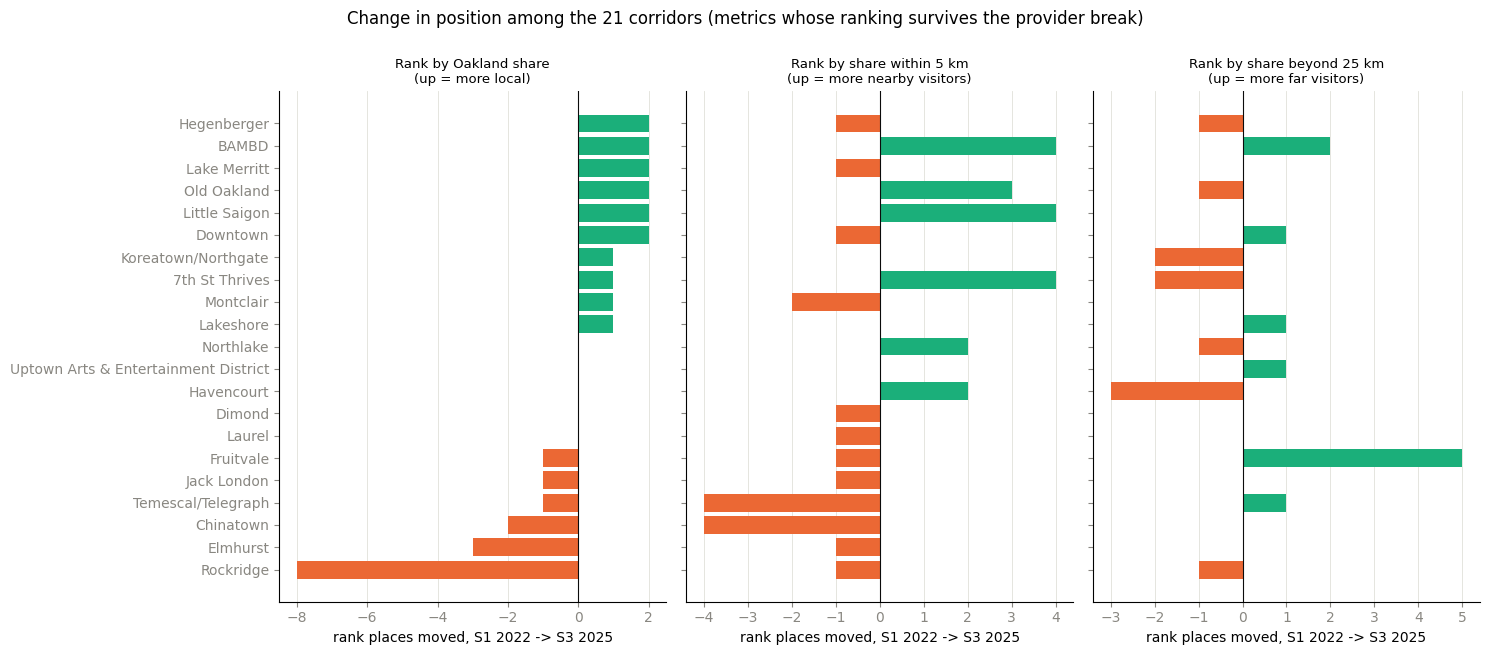

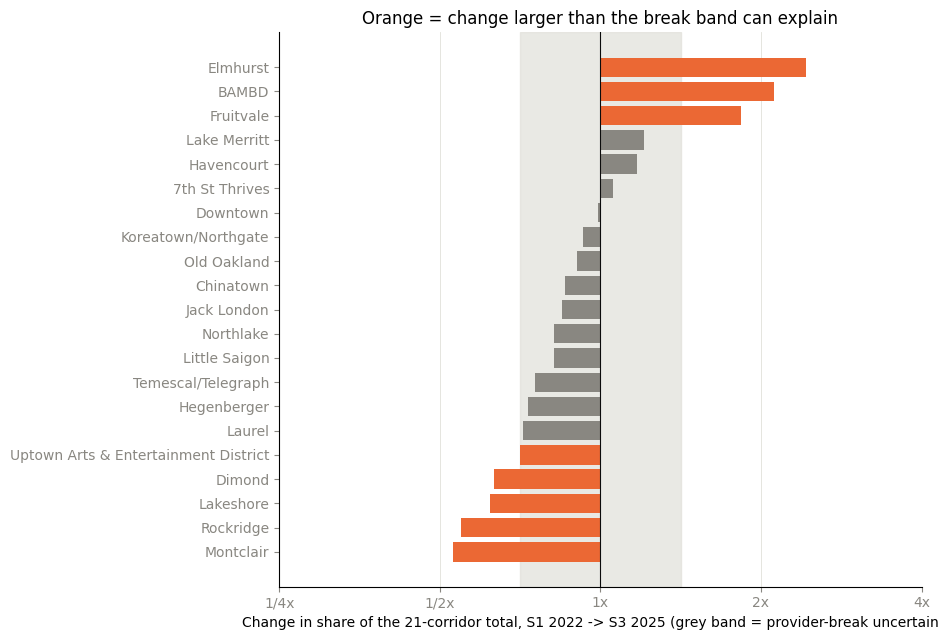

8 of 21 corridors change by more than the x1.42 band


,S1 2022,S3 2025,ratio,outside_band
name,,,,
Elmhurst,3.40,8.26,2.43,True
BAMBD,3.40,7.19,2.11,True
Fruitvale,5.53,10.14,1.83,True
Lake Merritt,7.96,9.60,1.21,False
Havencourt,4.51,5.29,1.17,False
7th St Thrives,2.33,2.46,1.06,False
Downtown,7.81,7.73,0.99,False
Koreatown/Northgate,4.61,4.28,0.93,False
Old Oakland,1.46,1.32,0.90,False


In [16]:
peer_change = pd.DataFrame({slug: C[slug]["peer_change"] for slug in C}).T
rules = meta["comparability"]["rules"]
band_factor = meta["comparability"]["share_band_factor"]
names_ = prof.name

metric_labels = {"oakland_pct": "Rank by Oakland share\n(up = more local)",
                 "within_5km_pct": "Rank by share within 5 km\n(up = more nearby visitors)",
                 "beyond_25km_pct": "Rank by share beyond 25 km\n(up = more far visitors)"}
fig, axes = plt.subplots(1, 3, figsize=(15, 6.5), sharey=True)
order = peer_change.sort_values("oakland_pct").index
for ax, (m, lab) in zip(axes, metric_labels.items()):
    v = peer_change.loc[order, m].astype(float)
    ax.barh(names_[order].values, v.values, color=np.where(v > 0, CATEGORICAL_PALETTE[2], CATEGORICAL_PALETTE[1]))
    ax.axvline(0, color="#0b0b0b", linewidth=0.8)
    ax.set_title(lab, fontsize=9.5)
    ax.set_xlabel("rank places moved, S1 2022 -> S3 2025")
    style_axis(ax, "x")
plt.suptitle("Change in position among the 21 corridors (metrics whose ranking survives the provider break)", y=1.0)
plt.tight_layout()
plt.show()

# activity level: share of total, S1 2022 -> S3 2025, with the break band
sh = pd.DataFrame({
    "S1 2022": {s: C[s]["segments"]["S1"]["summary"]["devices_share_pct"] for s in C},
    "S3 2025": {s: C[s]["segments"]["S3"]["summary"]["devices_share_pct"] for s in C},
})
sh["ratio"] = sh["S3 2025"] / sh["S1 2022"]
sh["outside_band"] = (sh.ratio > band_factor) | (sh.ratio < 1 / band_factor)
sh.index = names_[sh.index]

fig, ax = plt.subplots(figsize=(9.5, 6.5))
o = sh.sort_values("ratio")
ax.barh(o.index, np.log2(o.ratio), color=np.where(o.outside_band, CATEGORICAL_PALETTE[1], CHART_MUTED_TEXT))
ax.axvspan(-np.log2(band_factor), np.log2(band_factor), color=CHART_GRID_COLOR, alpha=0.7, zorder=0)
ax.axvline(0, color="#0b0b0b", linewidth=0.8)
ax.set_xticks([-2, -1, 0, 1, 2], ["1/4x", "1/2x", "1x", "2x", "4x"])
ax.set_xlabel("Change in share of the 21-corridor total, S1 2022 -> S3 2025 (grey band = provider-break uncertainty)")
ax.set_title("Orange = change larger than the break band can explain")
style_axis(ax, "x")
plt.tight_layout()
plt.show()
print(f"{int(sh.outside_band.sum())} of {len(sh)} corridors change by more than the x{band_factor:.2f} band")
sh.round(2).sort_values("ratio", ascending=False)

## Observations

*(All figures in sections 1-7 are the S3 provider's 2023H2-2025 shares and its 2025 levels; section 8 compares with S1.)*

**Scale.** Activity is very uneven. In 2025 the busiest corridors (Hegenberger, Fruitvale, Lake Merritt, Elmhurst, Downtown)
see roughly 5,900-8,800 estimated devices a month, while Montclair, Northlake and Uptown (small-sample, starred) see fewer
than 1,000 and Uptown fewer than 400. Size and intensity are different things: Fruitvale packs ~7,700 devices into
under 40 hectares, Lakeshore and Montclair are tiny but dense per hectare, and Hegenberger tops the count partly because
its polygon is by far the largest (about 350 ha), so it may include large nearby destinations and deserves a closer look
before being read as a "corridor" in the BID sense.

**Loyalty.** Repeat-visitor % and visits per device tell the same story (r = 0.95). Among corridors with enough data, repeat
rates range from about 18% (Lakeshore) to about 30% (Havencourt); Uptown's 10% is an outlier driven by a very small sample.
Loyalty is only weakly related to how far visitors travel (r about -0.2): Havencourt and Elmhurst are both local and loyal,
Downtown, Lake Merritt and BAMBD are as loyal with visitors travelling 9-12 km (plausibly regular workers and commuters),
while Rockridge and Lakeshore are local but have low repeat rates.

**When.** In 2023-25 almost every corridor sits close to the "no weekend skew" line (weekend share 26-30% against 28.6% for an
even week); only Hegenberger (26%) and Havencourt (27%) lean noticeably weekday, and Little Saigon, Rockridge and Jack London lean
slightly to weekends. Evening share varies much more, from about 34% (Chinatown) and 36% (Montclair) up to about 53-55% in
Elmhurst, Fruitvale, BAMBD and 7th St Thrives (Uptown, the most evening-oriented at 58%, is a small sample). The evening
window is shorter than the daytime one, so read these only relative to each other.

**Where from.** The Oakland share of visitors runs from about 34% (Uptown) to 67% (Laurel). The biggest non-Oakland source for
almost every corridor is the rest of the East Bay (roughly a quarter to a half of visitors), with San Francisco contributing
only about 3-9%. Corridors fall into a local group (Laurel, Dimond, Havencourt, Lakeshore, Montclair, Little Saigon, Elmhurst,
Fruitvale: 53-67% from Oakland, median distance 3-6 km) and a regional group (Uptown, Jack London, Chinatown, Hegenberger,
Downtown, Lake Merritt: 34-43% from Oakland, median 11-14 km). **Council district is a weak proxy for local draw:** even the most
local corridors get only about a third of their visitors from their own district (Havencourt 33%, Elmhurst 31%), and the biggest
gaps between "from Oakland" and "from own district" are in Dimond, Laurel and Lakeshore, whose Oakland visitors come from across the city.

**Time shifts reach.** Evening visitors come from closer to home than weekday-daytime visitors in **all 21 corridors** (by
about 3-4 km in Chinatown, Downtown and Lake Merritt), and in 19 of 21 they are also more likely to be Oakland residents.
Weekend visitors are slightly closer than weekday visitors in most corridors (18 of 21).

**Catchment shape.** The core catchment (the number of the 354 block groups needed to cover half of Oakland-origin visitors) is
tightest for 7th St Thrives (19), Elmhurst and Montclair (21) and BAMBD (26), and widest for Jack London (66), Lakeshore (64),
Uptown (63) and Chinatown (60). It is only loosely related to travel distance (r = 0.42).

**Types.** Clustering on distance, localness, loyalty, timing and size (S3 values) gives three groups that are driven more by volume
and loyalty than by localness: (1) **high-volume corridors** (Downtown, Chinatown, Lake Merritt, BAMBD, Hegenberger, Temescal/Telegraph and,
despite much shorter trips, Fruitvale, Elmhurst and Havencourt); (2) **small neighbourhood corridors** with the most local visitors
and lowest repeat rates (Montclair, Lakeshore, Laurel, Little Saigon, Dimond); and (3) **mid-size district destinations** with a higher evening
share (Koreatown/Northgate, Rockridge, Jack London, Old Oakland, Northlake, 7th St Thrives, Uptown). With 21 corridors and several small
samples, treat these as descriptive groupings. For localness itself, the Oakland-share and median-distance rankings above are clearer.

**Change relative to peers (section 8).** Across the provider break, rank *position* is only informative for share of the total
and the origin/distance bands, and most corridors move by three places or fewer on those. The clear exception is **Rockridge**, which
drops eight places in the local-to-regional ranking (from the middle of the pack to among the least local in 2025). In activity
share, 8 of 21 corridors change by more than the provider-break band: **Elmhurst (x2.4), BAMBD (x2.1) and Fruitvale (x1.8) gain
share, and Montclair, Rockridge, Lakeshore, Dimond and Uptown lose it**. A change that large is either real (a shift of activity toward
East Oakland) or a provider effect (the S3 panel covering different neighbourhoods better); the data cannot say which, which is why
these are flagged rather than reported as trends.